# EDA: цены aFRR Day-Ahead Capacity
**Автор:** Николай Давыдов

### описание колонок


| Переменная | Описание |
|---|---|
| **target_vwap_up** | Целевая переменная: Средневзвешенная по объёму цена (VWAP) aFRR в направлении вверх (UP) на венгерском рынке, €/МВт·ч. Если в данный час активации не было, значение равно 0. |
| **consumption** | Потребление электроэнергии, МВт·ч/ч (прогноз на сутки вперёд) |
| **wind** | Выработка ветровых станций, МВт·ч/ч (прогноз на сутки вперёд) |
| **solar** | Выработка солнечных станций, МВт·ч/ч (прогноз на сутки вперёд) |
| **nuclear** | Выработка АЭС, МВт·ч/ч (прогноз на сутки вперёд) |
| **temperature** | Температура, °C (прогноз на сутки вперёд) |
| **exchange_net_export** | Чистый экспорт (перетоки с соседними странами), МВт·ч/ч (прогноз на сутки вперёд) |
| **carbon_intensity_production** | Углеродоёмкость производства, кгCO₂-экв/МВт·ч (прогноз на сутки вперёд) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.db import get_db_engine

%matplotlib inline

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.max_columns", 50)

In [2]:
# Чтение данных
engine = get_db_engine()
df = pd.read_sql("SELECT * FROM afrr_prices ORDER BY datetime;", engine)

print(f"Загружено строк: {len(df):,}; столбцов: {df.shape[1]}")
df

Загружено строк: 26,304; столбцов: 9


,datetime,consumption,wind,solar,nuclear,temperature,exchange_net_export,carbon_intensity_production,target_vwap_up
0,2023-01-01 00:00:00+00:00,3849.30,124.03,0.0,1900.0,5.23,-900.0,None,0.00
1,2023-01-01 01:00:00+00:00,3625.20,119.20,0.0,1900.0,5.30,-702.1,None,0.00
2,2023-01-01 02:00:00+00:00,3442.88,121.98,0.0,1900.0,4.91,-540.6,None,0.00
3,2023-01-01 03:00:00+00:00,3397.08,125.50,0.0,1900.0,4.51,-900.0,None,0.00
4,2023-01-01 04:00:00+00:00,3442.40,126.23,0.0,1900.0,4.51,-721.3,None,0.00
...,...,...,...,...,...,...,...,...,...
26299,2025-12-31 19:00:00+00:00,5242.05,122.05,0.0,1920.0,-2.60,-1944.2,None,1.48
26300,2025-12-31 20:00:00+00:00,5291.80,132.15,0.0,1920.0,-2.44,-1999.6,None,0.76
26301,2025-12-31 21:00:00+00:00,5277.38,138.50,0.0,1920.0,-2.29,-1974.3,None,0.54
26302,2025-12-31 22:00:00+00:00,5230.78,145.45,0.0,1920.0,-2.11,-1925.5,None,0.00


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26304 entries, 0 to 26303
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   datetime                     26304 non-null  str    
 1   consumption                  26304 non-null  float64
 2   wind                         26304 non-null  float64
 3   solar                        26304 non-null  float64
 4   nuclear                      26304 non-null  float64
 5   temperature                  26304 non-null  float64
 6   exchange_net_export          26304 non-null  float64
 7   carbon_intensity_production  0 non-null      object 
 8   target_vwap_up               26304 non-null  float64
dtypes: float64(7), object(1), str(1)
memory usage: 2.4+ MB


## 1. Структура и качество данных

Проверим период, частоту, дубликаты, пропущенные часы и типы данных.

In [4]:
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
df = df.sort_values("datetime").set_index("datetime")

print(f"Период: {df.index.min()} — {df.index.max()}")
print(f"Строк: {len(df):,}; столбцов: {df.shape[1]}")
print(f"Дубликатов по времени: {df.index.duplicated().sum()}")

gaps = df.index.to_series().diff().dt.total_seconds().div(3600)
print(f"Разрывов больше 1 часа: {(gaps > 1).sum()}")

print("\nТипы данных:")
print(df.dtypes)

print("\nОписательные статистики:")
display(df.describe().T.round(2))

Период: 2023-01-01 00:00:00+00:00 — 2025-12-31 23:00:00+00:00
Строк: 26,304; столбцов: 8
Дубликатов по времени: 0
Разрывов больше 1 часа: 0

Типы данных:
consumption                    float64
wind                           float64
solar                          float64
nuclear                        float64
temperature                    float64
exchange_net_export            float64
carbon_intensity_production     object
target_vwap_up                 float64
dtype: object

Описательные статистики:


,count,mean,std,min,25%,50%,75%,max
consumption,26304.0,4892.35,824.54,2342.18,4266.62,4827.59,5445.61,7336.58
wind,26304.0,67.77,62.83,0.55,17.65,48.04,99.25,298.60
solar,26304.0,614.15,901.69,0.00,0.00,30.09,1045.03,4179.00
nuclear,26304.0,1731.61,236.13,956.00,1428.00,1900.00,1900.00,1949.50
temperature,26304.0,12.53,9.21,-7.29,4.85,12.14,19.76,35.91
exchange_net_export,26304.0,-1130.76,1227.78,-5365.30,-1988.32,-1300.00,-436.25,3819.90
target_vwap_up,26304.0,23.44,44.14,0.00,1.02,3.86,21.75,213.75


## 2. Пропуски

Проверим, какие признаки содержат пропуски и можно ли их использовать в модели.

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
display(pd.DataFrame({"Пропусков": missing, "Доля, %": missing_pct}))

print("Уникальные значения carbon_intensity_production:",
      df["carbon_intensity_production"].dropna().unique())

df = df.drop(columns=["carbon_intensity_production"])
print("\nСтолбец carbon_intensity_production удалён: он полностью пуст.")

,Пропусков,"Доля, %"
carbon_intensity_production,26304,100.0
consumption,0,0.0
wind,0,0.0
solar,0,0.0
nuclear,0,0.0
temperature,0,0.0
exchange_net_export,0,0.0
target_vwap_up,0,0.0


Уникальные значения carbon_intensity_production: []

Столбец carbon_intensity_production удалён: он полностью пуст.


## 3. Целевая переменная `target_vwap_up`

Посмотрим на распределение, долю нулевых значений и выбросы.

,target_vwap_up
count,26304.00
mean,23.44
std,44.14
min,0.00
50%,3.86
90%,76.95
95%,138.60
99%,198.01
max,213.75


Доля нулей: 11.0%
Доля положительных значений: 89.0%


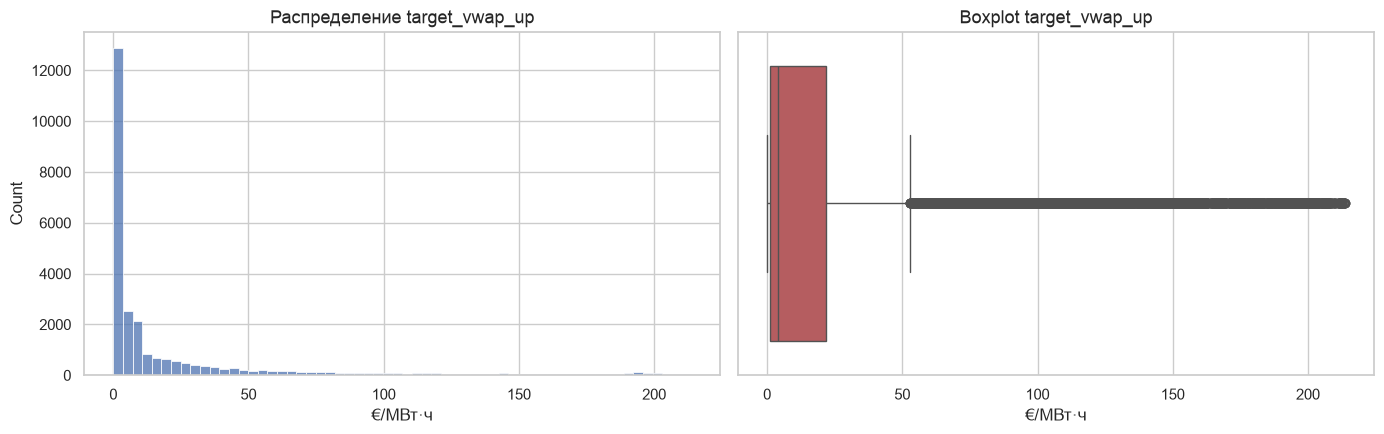

In [6]:
target = df["target_vwap_up"]
zero_share = (target == 0).mean()

display(target.describe(percentiles=[.5, .9, .95, .99]).to_frame("target_vwap_up").round(2))
print(f"Доля нулей: {zero_share:.1%}")
print(f"Доля положительных значений: {(target > 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(target, bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Распределение target_vwap_up")
axes[0].set_xlabel("€/МВт·ч")

sns.boxplot(x=target, ax=axes[1], color="#C44E52")
axes[1].set_title("Boxplot target_vwap_up")
axes[1].set_xlabel("€/МВт·ч")

plt.tight_layout()
# plt.savefig(PROJECT_ROOT / "reports/figures/01_target_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Сезонность

Добавим календарные признаки и посмотрим на среднюю цену по месяцам, часам, дням недели и годам.

In [7]:
df["year"] = df.index.year
df["month"] = df.index.month
df["hour"] = df.index.hour
df["weekday"] = df.index.dayofweek
df["date"] = df.index.date

monthly = df.groupby("month")["target_vwap_up"].agg(["mean", "median", "max", lambda s: (s == 0).mean()])
monthly.columns = ["Среднее", "Медиана", "Максимум", "Доля нулей"]

hourly = df.groupby("hour")["target_vwap_up"].agg(["mean", "median", "max", lambda s: (s == 0).mean()])
hourly.columns = ["Среднее", "Медиана", "Максимум", "Доля нулей"]

weekday_names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
weekday = df.groupby("weekday")["target_vwap_up"].agg(["mean", "median"])
weekday.index = weekday_names
weekday.columns = ["Среднее", "Медиана"]

yearly = df.groupby("year")["target_vwap_up"].agg(["mean", "median", "max", lambda s: (s == 0).mean()])
yearly.columns = ["Среднее", "Медиана", "Максимум", "Доля нулей"]

print("По месяцам:")
display(monthly.round(2))
print("По часам (UTC):")
display(hourly.round(2))
print("По дням недели:")
display(weekday.round(2))
print("По годам:")
display(yearly.round(2))

По месяцам:


,Среднее,Медиана,Максимум,Доля нулей
month,,,,
1,11.10,1.44,190.68,0.38
2,14.88,1.05,198.34,0.33
3,14.73,1.18,197.11,0.35
4,24.14,6.72,211.20,0.14
5,36.92,7.72,213.61,0.02
6,28.28,3.25,213.75,0.03
7,15.86,3.78,209.58,0.01
8,32.07,2.85,207.30,0.02
9,35.07,9.18,203.85,0.02


По часам (UTC):


,Среднее,Медиана,Максимум,Доля нулей
hour,,,,
0,1.89,1.01,39.22,0.11
1,1.86,1.02,39.47,0.12
2,1.88,1.01,38.98,0.11
3,1.94,1.04,37.84,0.11
4,2.71,1.23,54.08,0.10
5,22.79,6.95,209.58,0.10
6,49.55,26.75,213.75,0.10
7,51.66,28.38,213.61,0.11
8,49.68,26.38,213.48,0.10


По дням недели:


,Среднее,Медиана
Пн,24.08,4.12
Вт,21.88,3.83
Ср,21.05,3.41
Чт,20.62,3.26
Пт,19.54,3.46
Сб,28.10,4.77
Вс,28.78,4.51


По годам:


,Среднее,Медиана,Максимум,Доля нулей
year,,,,
2023,29.89,5.42,213.75,0.30
2024,26.27,3.08,207.27,0.02
2025,14.14,2.74,198.34,0.01


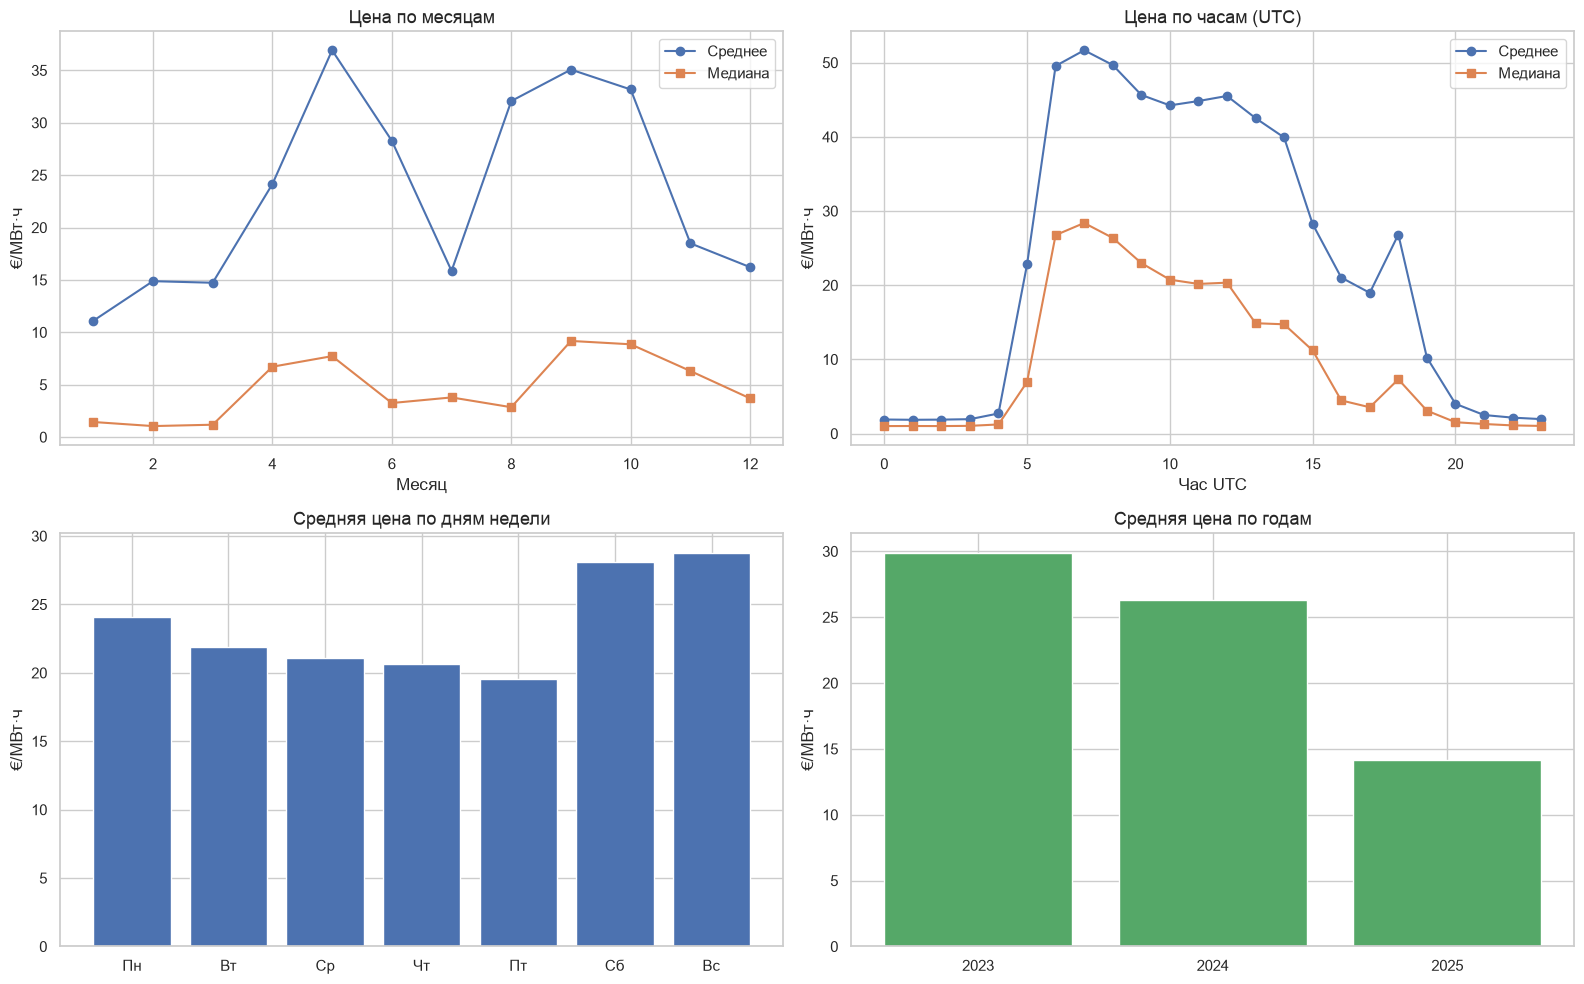

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(monthly.index, monthly["Среднее"], marker="o", label="Среднее")
axes[0, 0].plot(monthly.index, monthly["Медиана"], marker="s", label="Медиана")
axes[0, 0].set_title("Цена по месяцам")
axes[0, 0].set_xlabel("Месяц")
axes[0, 0].set_ylabel("€/МВт·ч")
axes[0, 0].legend()

axes[0, 1].plot(hourly.index, hourly["Среднее"], marker="o", label="Среднее")
axes[0, 1].plot(hourly.index, hourly["Медиана"], marker="s", label="Медиана")
axes[0, 1].set_title("Цена по часам (UTC)")
axes[0, 1].set_xlabel("Час UTC")
axes[0, 1].set_ylabel("€/МВт·ч")
axes[0, 1].legend()

axes[1, 0].bar(weekday.index, weekday["Среднее"], color="#4C72B0")
axes[1, 0].set_title("Средняя цена по дням недели")
axes[1, 0].set_ylabel("€/МВт·ч")

axes[1, 1].bar(yearly.index.astype(str), yearly["Среднее"], color="#55A868")
axes[1, 1].set_title("Средняя цена по годам")
axes[1, 1].set_ylabel("€/МВт·ч")

plt.tight_layout()
plt.show()

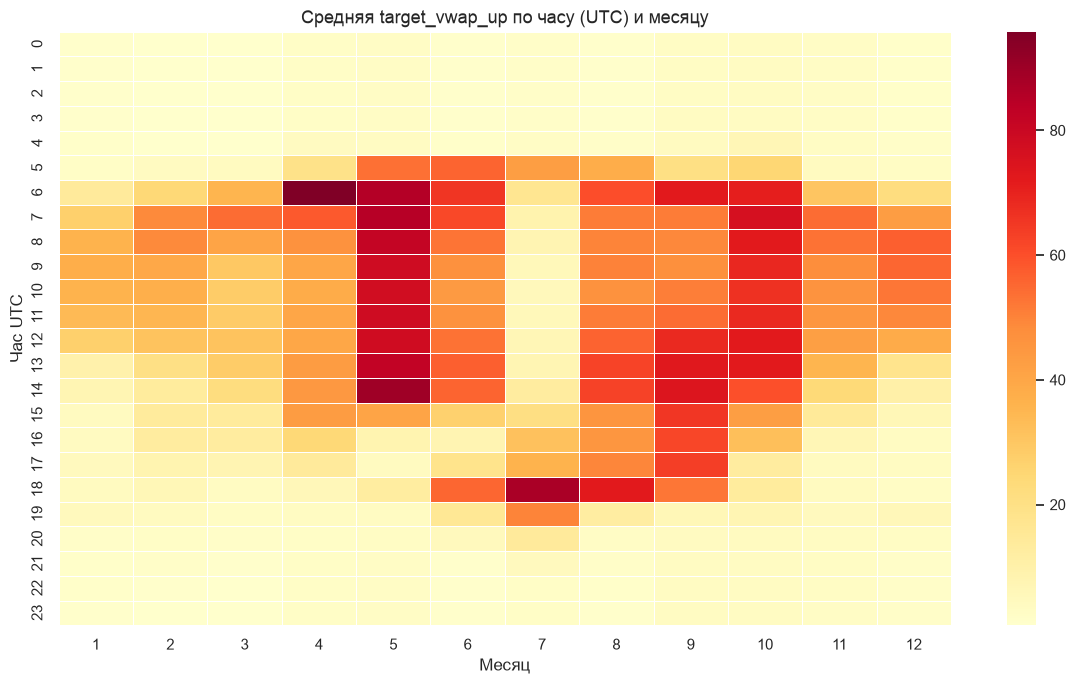

In [9]:
pivot = df.pivot_table(index="hour", columns="month", values="target_vwap_up", aggfunc="mean")

plt.figure(figsize=(12, 7))
sns.heatmap(pivot, cmap="YlOrRd", linewidths=0.5)
plt.title("Средняя target_vwap_up по часу (UTC) и месяцу")
plt.xlabel("Месяц")
plt.ylabel("Час UTC")
plt.tight_layout()
plt.show()

### Сезонность признаков

Посмотрим, как ведут себя основные факторы по месяцам.

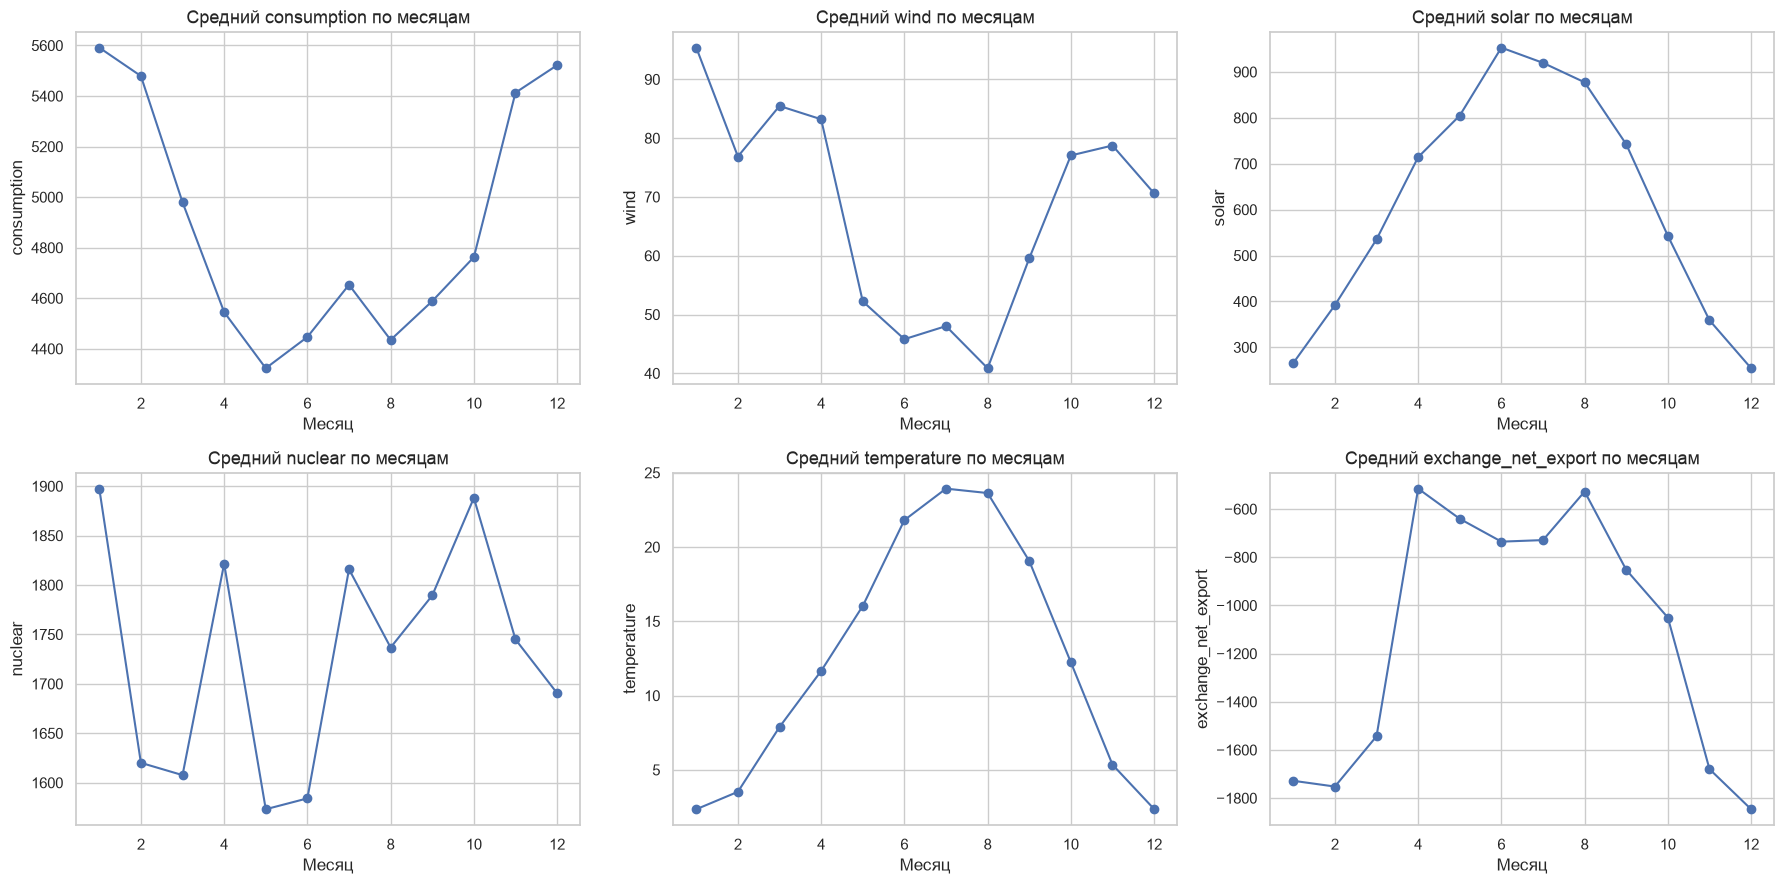

In [10]:
features = ["consumption", "wind", "solar", "nuclear", "temperature", "exchange_net_export"]
monthly_features = df.groupby("month")[features].mean()

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), features):
    ax.plot(monthly_features.index, monthly_features[col], marker="o", color="#4C72B0")
    ax.set_title(f"Средний {col} по месяцам")
    ax.set_xlabel("Месяц")
    ax.set_ylabel(col)
    ax.grid(True)

plt.tight_layout()
plt.show()

## 5. Динамика цены во времени

Посмотрим на суточную и месячную динамику, а также на долю нулевых часов.

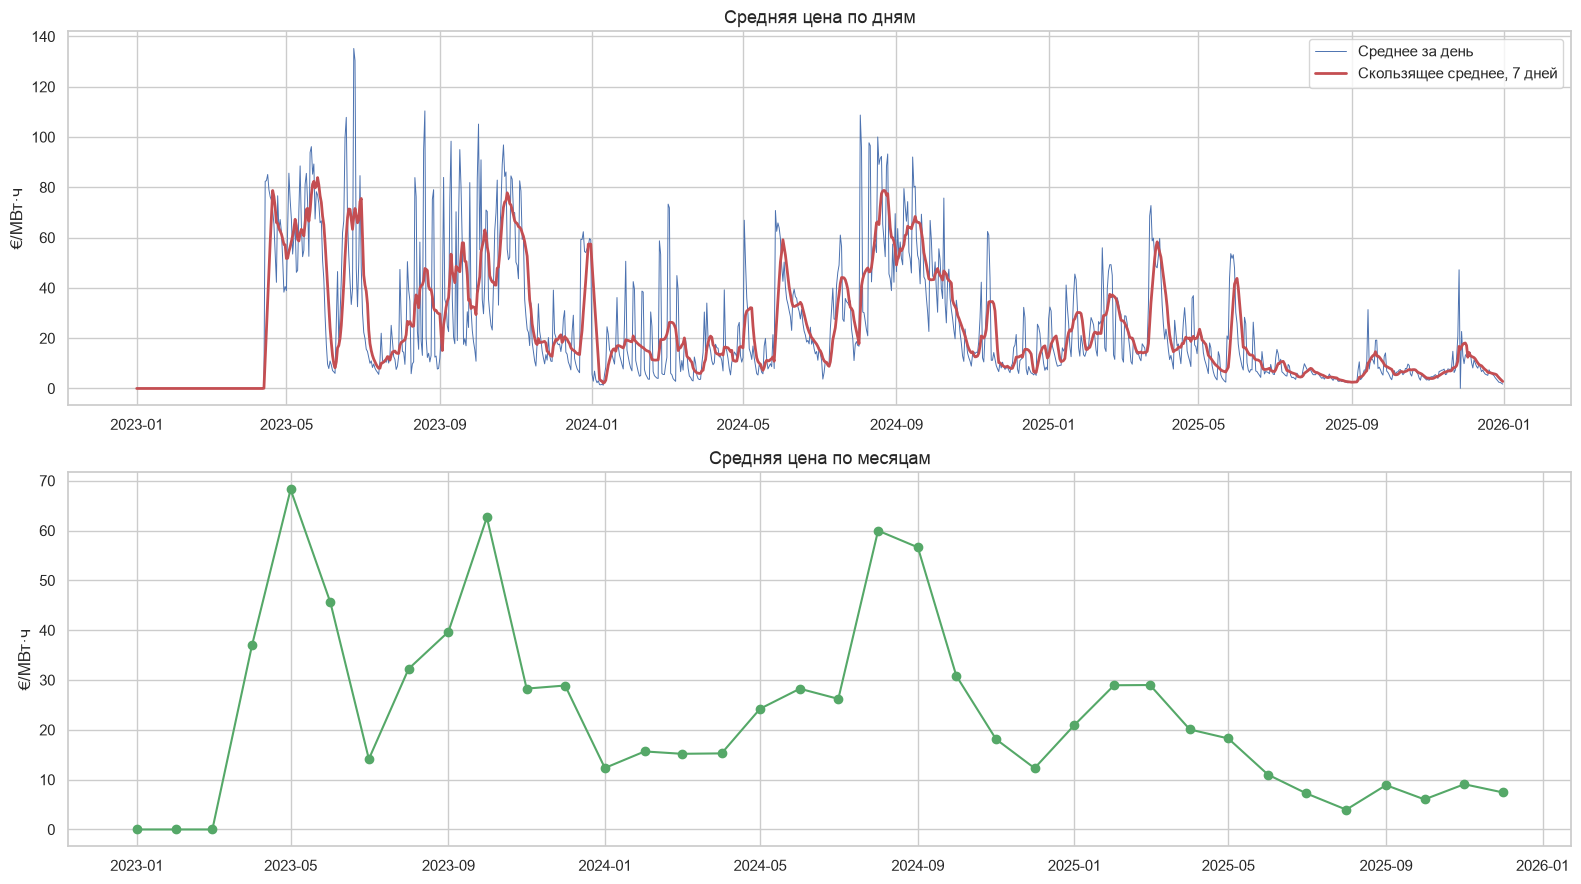

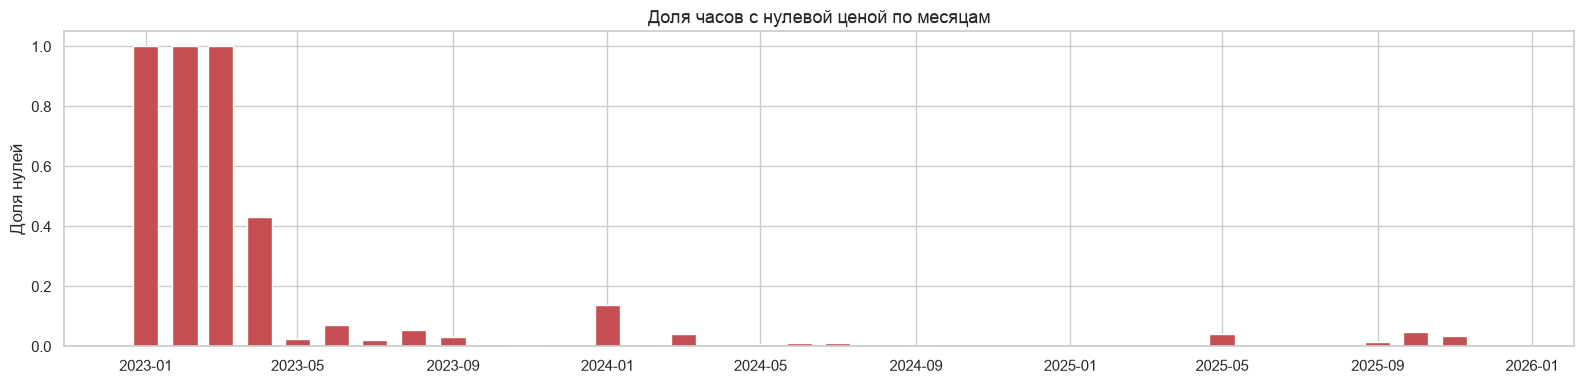

In [11]:
daily = df["target_vwap_up"].resample("D").mean()
daily_roll = daily.rolling(7, min_periods=1).mean()
monthly_series = df["target_vwap_up"].resample("MS").mean()
zero_monthly = df["target_vwap_up"].resample("MS").apply(lambda s: (s == 0).mean())

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

axes[0].plot(daily.index, daily.values, lw=0.7, color="#4C72B0", label="Среднее за день")
axes[0].plot(daily_roll.index, daily_roll.values, lw=2, color="#C44E52", label="Скользящее среднее, 7 дней")
axes[0].set_title("Средняя цена по дням")
axes[0].set_ylabel("€/МВт·ч")
axes[0].legend()

axes[1].plot(monthly_series.index, monthly_series.values, marker="o", color="#55A868")
axes[1].set_title("Средняя цена по месяцам")
axes[1].set_ylabel("€/МВт·ч")

plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 4))
plt.bar(zero_monthly.index, zero_monthly.values, width=20, color="#C44E52")
plt.title("Доля часов с нулевой ценой по месяцам")
plt.ylabel("Доля нулей")
plt.tight_layout()
plt.show()

## 6. Выбросы

Оценим выбросы методом межквартильного размаха (IQR): значения ниже `Q1 - 1.5·IQR` или выше `Q3 + 1.5·IQR`.

,Q1,Q3,Нижняя граница,Верхняя граница,Выбросов,"Доля, %"
Признак,,,,,,
consumption,4266.62,5445.61,2498.13,7214.10,15,0.06
wind,17.65,99.25,-104.75,221.65,923,3.51
solar,0.00,1045.03,-1567.55,2612.59,1373,5.22
nuclear,1428.00,1900.00,720.00,2608.00,0,0.00
temperature,4.85,19.76,-17.52,42.12,0,0.00
exchange_net_export,-1988.32,-436.25,-4316.44,1891.86,601,2.28
target_vwap_up,1.02,21.75,-30.08,52.85,3633,13.81


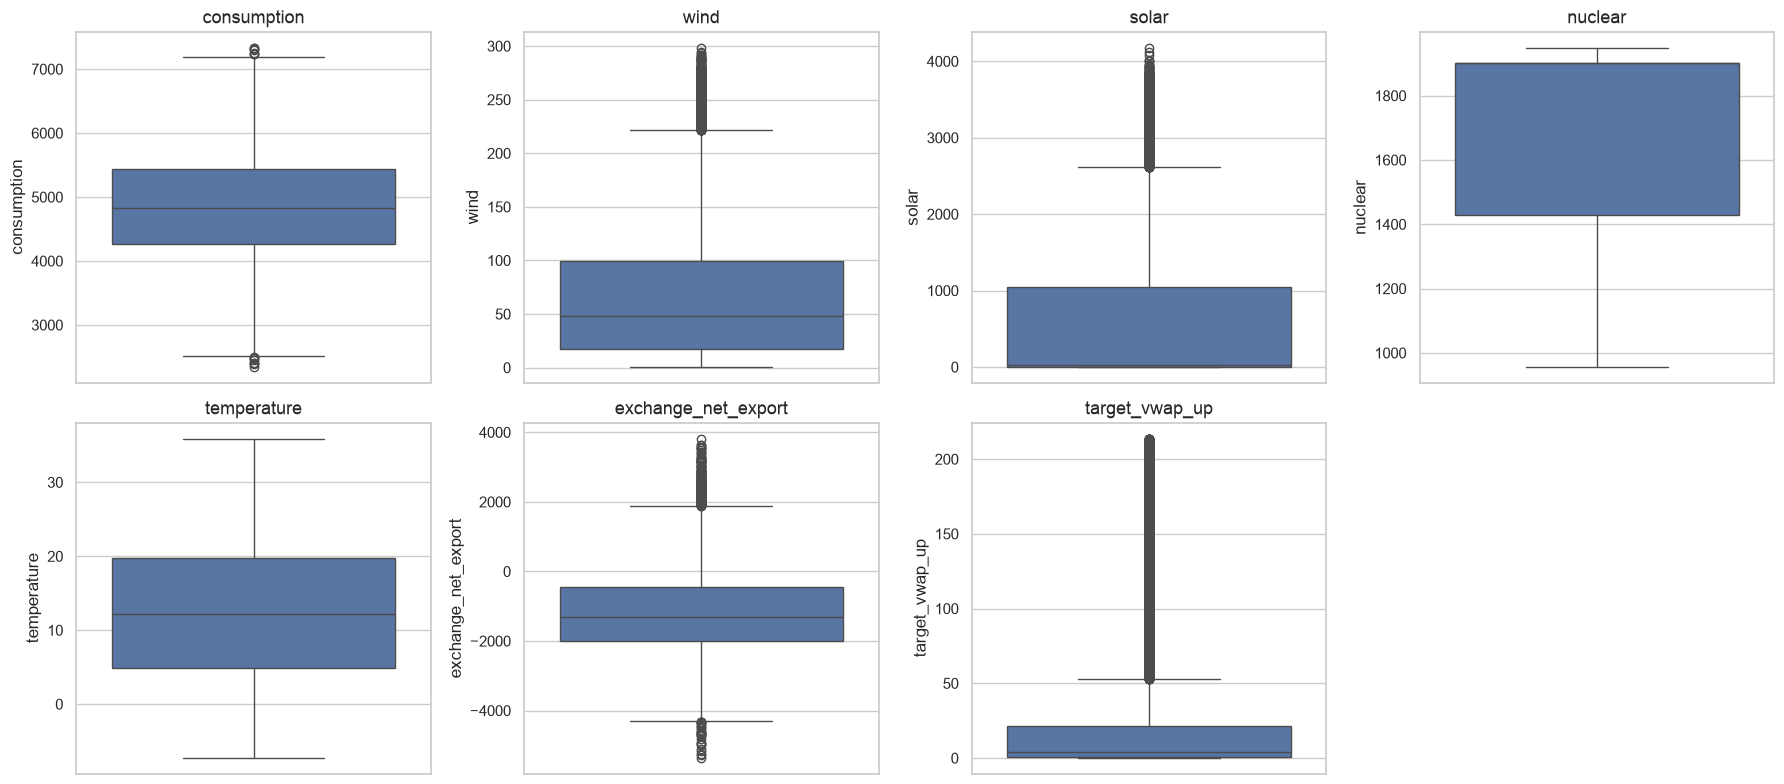

In [12]:
cols = ["consumption", "wind", "solar", "nuclear", "temperature", "exchange_net_export", "target_vwap_up"]

outlier_rows = []
for col in cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[col] < lo) | (df[col] > hi)).sum())
    outlier_rows.append({
        "Признак": col,
        "Q1": q1,
        "Q3": q3,
        "Нижняя граница": lo,
        "Верхняя граница": hi,
        "Выбросов": n,
        "Доля, %": n / len(df) * 100,
    })

outliers = pd.DataFrame(outlier_rows).set_index("Признак")
display(outliers.round(2))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0")
    ax.set_title(col)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 7. Взаимосвязи признаков

Построим корреляционные матрицы Пирсона и Спирмена, а также диаграммы рассеяния относительно целевой переменной.

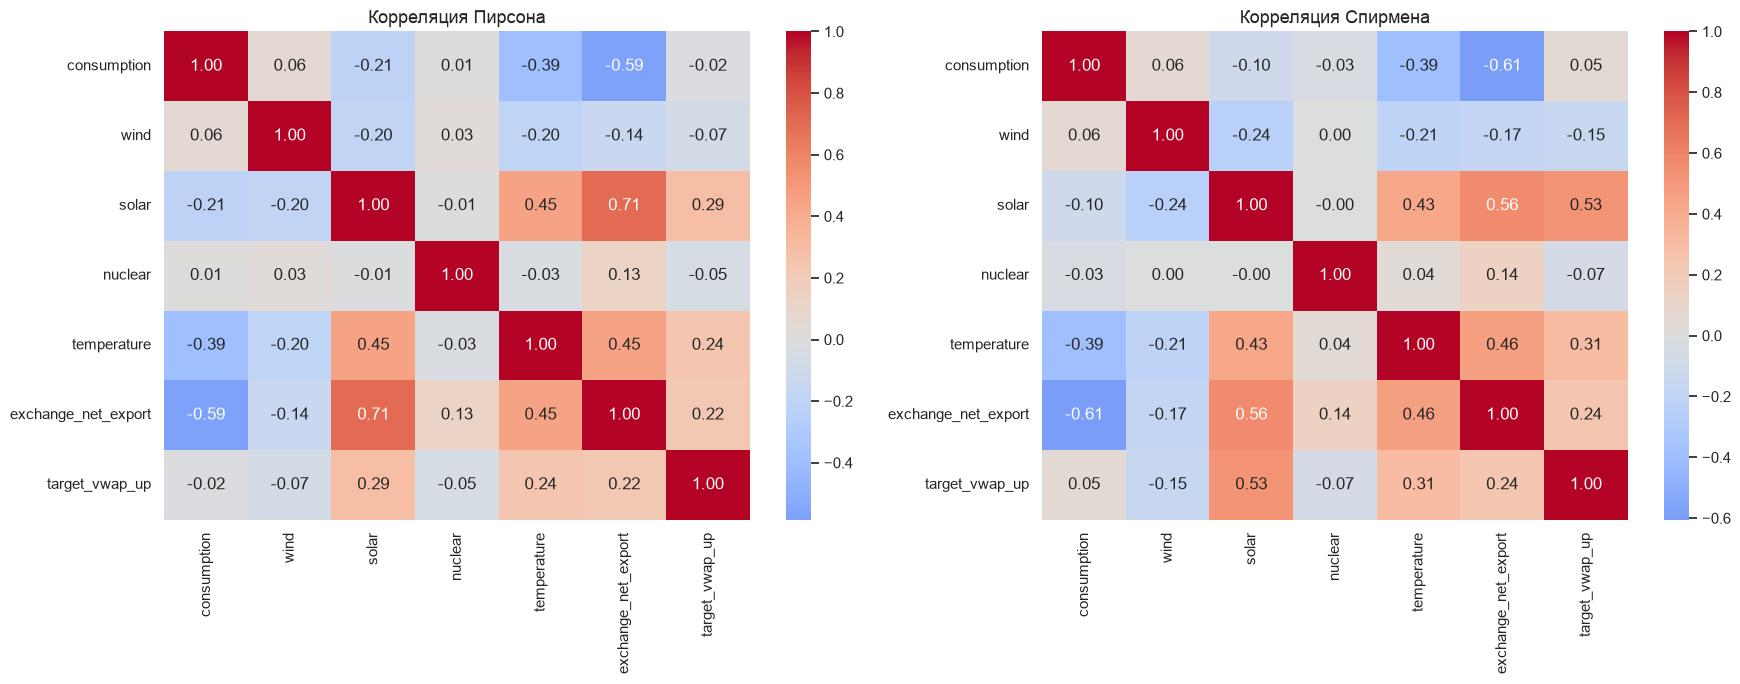

Корреляция признаков с target_vwap_up (Пирсон):


,Pearson
target_vwap_up,1.000
solar,0.293
temperature,0.236
exchange_net_export,0.221
consumption,-0.018
nuclear,-0.049
wind,-0.074


Корреляция признаков с target_vwap_up (Спирмен):


,Spearman
target_vwap_up,1.000
solar,0.529
temperature,0.306
exchange_net_export,0.239
consumption,0.049
nuclear,-0.066
wind,-0.153


In [13]:
pearson = df[cols].corr(method="pearson")
spearman = df[cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Корреляция Пирсона")
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Корреляция Спирмена")

plt.tight_layout()
plt.show()

print("Корреляция признаков с target_vwap_up (Пирсон):")
display(pearson["target_vwap_up"].sort_values(ascending=False).to_frame("Pearson").round(3))
print("Корреляция признаков с target_vwap_up (Спирмен):")
display(spearman["target_vwap_up"].sort_values(ascending=False).to_frame("Spearman").round(3))

## 8. Сравнение часов с нулевой и ненулевой ценой

Проверим, чем отличаются часы, когда активаций не было (`target_vwap_up = 0`), от часов с положительной ценой.

target_is_zero,Цена > 0,Цена = 0,Разница
consumption,4864.40,5117.69,-253.30
wind,65.36,87.19,-21.83
solar,658.18,259.24,398.94
nuclear,1727.57,1764.24,-36.68
temperature,13.36,5.83,7.53
exchange_net_export,-1077.78,-1557.81,480.03
target_vwap_up,26.35,0.00,26.35


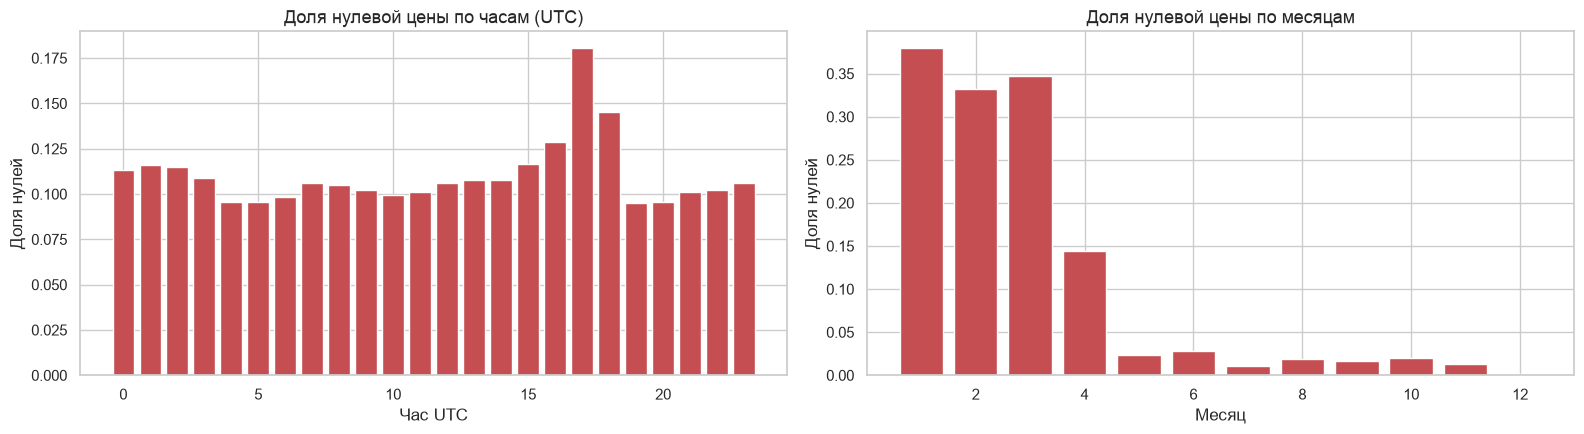

In [14]:
df["target_is_zero"] = df["target_vwap_up"] == 0

comparison = (
    df.groupby("target_is_zero")[cols]
      .mean()
      .T
)
comparison = comparison.rename(columns={False: "Цена > 0", True: "Цена = 0"})
comparison["Разница"] = comparison["Цена > 0"] - comparison["Цена = 0"]
display(comparison.round(2))

zero_by_hour = df.groupby("hour")["target_is_zero"].mean()
zero_by_month = df.groupby("month")["target_is_zero"].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].bar(zero_by_hour.index, zero_by_hour.values, color="#C44E52")
axes[0].set_title("Доля нулевой цены по часам (UTC)")
axes[0].set_xlabel("Час UTC")
axes[0].set_ylabel("Доля нулей")

axes[1].bar(zero_by_month.index, zero_by_month.values, color="#C44E52")
axes[1].set_title("Доля нулевой цены по месяцам")
axes[1].set_xlabel("Месяц")
axes[1].set_ylabel("Доля нулей")

plt.tight_layout()
plt.show()

## 9. Выводы

1. **Качество данных.** В таблице `afrr_prices` 26 304 часовых наблюдения за период
   с 2023-01-01 по 2025-12-31 (UTC). Дубликатов и пропущенных часов нет.
   Признак `carbon_intensity_production` полностью пуст и исключён из анализа.

2. **Целевая переменная сильно скошена вправо.** Среднее значение ≈ 23.44 €/МВт·ч,
   медиана ≈ 3.86 €/МВт·ч, максимум ≈ 213.75 €/МВт·ч. Около 11% часов имеют
   нулевую цену (в 2023 году — 30%, в 2024–2025 — около 1–2%). Для моделирования
   стоит рассмотреть `log1p`-преобразование и отдельную модель/классификатор
   для предсказания нулевых активаций.

3. **Выражена суточная сезонность.** Цена минимальна ночью (00–04 UTC), резко
   растёт утром (05–06 UTC) и достигает максимума в 06–12 UTC; вечером снова
   снижается. Это согласуется с профилем потребления и генерации солнечной энергии.

4. **Выражена годовая сезонность.** Наиболее высокие средние цены — весной и
   осенью (апрель–май, сентябрь–октябрь), самый низкий уровень — зимой и в июле.
   Доля нулевых значений максимальна в январе–марте. Средняя цена снижается
   от 2023 года (≈ 29.9) к 2025 году (≈ 14.1). Выходные в среднем дороже
   будней: ≈ 28–29 €/МВт·ч против ≈ 20–24 €/МВт·ч.

5. **Наиболее связанные с ценой признаки:** `solar` (Пирсон +0.29, Спирмен +0.53),
   `temperature` (+0.24 / +0.31), `exchange_net_export` (+0.22 / +0.24).
   `wind` имеет слабую отрицательную связь (−0.07 / −0.15), а `consumption`
   практически не коррелирует с ценой линейно. Для нелинейных моделей
   (бустинги, нейросети) эти признаки всё равно могут быть полезны.

6. **Выбросы.** По правилу IQR много выбросов у `solar` (~5.2%), `wind` (~3.5%),
   `exchange_net_export` (~2.3%) и `target_vwap_up` (~13.8%). Для погодных и
   рыночных рядов это, как правило, не ошибки, а экстремальные, но реальные
   режимы. Их не следует удалять без отдельного анализа; лучше использовать
   устойчивые к выбросам модели и/или логарифмирование цели.

7. **Практические выводы для моделирования:**
   - добавить календарные признаки: час, день недели, месяц, праздники;
   - использовать лаги и скользящие статистики цены с осторожностью, чтобы
     не допустить утечки данных (прогноз строится на сутки вперёд);
   - валидировать модель по времени (например, последний год — тест);
   - проверить `log1p`-преобразование цели и двухэтапную схему
     «вероятность нуля + регрессия положительной цены»;
   - признаки `solar`, `temperature`, `exchange_net_export` — приоритетные
     кандидаты для feature engineering.

8. **Нулевые и ненулевые часы различаются по профилю факторов.** В часы с нулевой
   ценой в среднем меньше солнечной генерации (259 против 658 МВт·ч/ч), выше
   температура (13.4 против 5.8 °C), меньше чистый экспорт (−1078 против −1558
   МВт·ч/ч) и чуть ниже потребление (4864 против 5118 МВт·ч/ч). Это подтверждает
   целесообразность отдельного моделирования факта нулевой активации.